# Julia から Wolfram Engine を呼び出す — ベクトル・図形を Julia で使う

[MathLink.jl](https://github.com/JuliaInterop/MathLink.jl) を使って Julia から Wolfram Engine を呼び出します（積分・微分・方程式・数列・確率・複素数平面・微分方程式編の続き）。

Julia では配列 `[1, 2]` がそのままベクトルです。Wolfram の**厳密な値**を Julia のベクトルとして受け取り，計算と図示に使います。

- ベクトルの計算：内積・大きさ・なす角を厳密に求める
- 三角形：面積，重心・外心・内心・垂心，外接円・内接円
- 直線と円：交点，点と直線の距離，接線
- 空間：外積，平面の方程式，点と平面の距離，直線と平面の交点，四面体の体積
- 数式は $\LaTeX$ 組版（TraditionalForm 相当）で表示する

**注意**：無料版 Wolfram Engine は同時に起動できるカーネル数に上限があります。他のノートブックや `wolframscript` が動いたままだと接続に失敗するので，使い終わったカーネルは停止してください。

## 0. 準備

共通の関数（表示 `tex`, `showtex`，変換 `to_expr`, `to_value`, `to_function` など）は `wolfram_common.jl` にまとめてあります。  
このノートブックと同じフォルダに置いて，`include` で読み込みます。初回だけパッケージを追加します（追加済みなら次のセルは実行不要）。

In [1]:
# import Pkg; Pkg.add(["MathLink", "Plots"])

In [2]:
include("wolfram_common.jl")      # MathLink の読み込みと，共通の関数（表示・変換）
using LinearAlgebra       # Julia の dot, cross, norm, det（検算用）
using Plots

## 1. 基本：Wolfram と Julia のベクトル

| | Wolfram | Julia |
|---|---|---|
| ベクトル | `{1, 2}` | `[1, 2]` |
| 内積 | `{1, 2}.{3, 4}` または `Dot[a, b]` | `dot(a, b)` または `a ⋅ b` |
| 大きさ | `Norm[a]` | `norm(a)` |
| 外積 | `Cross[a, b]` | `cross(a, b)` または `a × b` |

In [3]:
weval(W`{1, 2}.{3, 4}`), weval(W`Norm[{1, Sqrt[3]}]`)

(11, 2)

In [4]:
weval(W`VectorAngle[{1, Sqrt[3]}, {Sqrt[3], 1}]`)       # なす角（厳密）

W`Times[Rational[1, 6], Pi]`

In [5]:
# Julia では近似値になる
a, b = [1, sqrt(3)], [sqrt(3), 1]
dot(a, b), norm(a), acos(dot(a, b) / (norm(a) * norm(b))), π / 6

(3.4641016151377544, 1.9999999999999998, 0.5235987755982985, 0.5235987755982988)

## 2. きれいに表示するための関数

`calc("Wolfram の式")` は，入力した式と評価結果を「左辺 = 右辺」で表示し，結果を返します。  
ベクトルは成分表示 $(1,\ 2)$ で表示します。左辺を自分で書きたいときは `lhs="..."`（$\LaTeX$）で指定します。

In [6]:
# リスト {1, 2} を成分表示 (1, 2) に，内積の . を ・ に，大きさ ‖ ‖ を | | にする
function vtex(s)
    s = replace(s, "\\}.\\{" => "\\}\\cdot\\{", "\\right\\}.\\left\\{" => "\\right\\}\\cdot\\left\\{",
                   "\\}.\\left\\{" => "\\}\\cdot\\left\\{", "\\right\\}.\\{" => "\\right\\}\\cdot\\{")
    replace(s, "\\left\\{" => "\\left(", "\\right\\}" => "\\right)", "\\{" => "(", "\\}" => ")", "\\|" => "|")
end

# Wolfram 言語の文字列 → 評価せずに LaTeX 文字列（入力した形のまま表示する）
texheld(s::AbstractString) = vtex(heldtex(s))

# 点のリスト {{1, 2}, {3, 4}} → (1, 2), (3, 4)
ptstex(w) = join(vtex.(tex.(w.args)), ",\\ \\ ")

# 規則のリスト {s -> 1, t -> 2} → s = 1, t = 2
ruletex(w) = join((tex(r.args[1]) * " = " * tex(r.args[2]) for r in w.args), ",\\quad ")

# 「左辺 = 評価結果」を表示して，結果（Wolfram の式）を返す
function calc(cmd::AbstractString; lhs=nothing, simplify=false)
    res = weval(MathLink.parseexpr(cmd))
    simplify && (res = weval(W"FullSimplify"(res)))
    showtex((lhs === nothing ? texheld(cmd) : lhs) * " = " * vtex(tex(res)))
    return res
end

calc (generic function with 1 method)

In [7]:
calc("2 {1, 2} - 3 {-1, 4}")
calc("{1, 2}.{3, 4}")
calc("Norm[{1, Sqrt[3]}]")
calc("Cross[{1, 2, 3}, {4, 5, 6}]")
calc("VectorAngle[{1, Sqrt[3]}, {Sqrt[3], 1}]"; lhs="\\theta");

## 3. Wolfram の式を Julia の式・関数に変換する

変換の関数は，共通ファイル `wolfram_common.jl` にまとめてあります（0 節の `include` で読み込み済み）。

- `to_expr(w)`：Wolfram の式 → Julia の式（`Expr`）
- `to_value(w)`：Wolfram の式 → Julia の値
- `to_function(w, :x, ...)`：Wolfram の式 → Julia の関数
- 対応表 `WFUNC`（Wolfram の関数名 → Julia の関数名）に無い関数が出てきたら，`WFUNC["名前"] = :Juliaの関数名` で追加できます。

このノートブックで特に使う変換：

- リスト `{1, 2}` → Julia のベクトル `[1, 2]`，点のリスト `{{0, 0}, {4, 0}}` → ベクトルのベクトル
- 規則のリスト `{x -> 3, y -> 4}` → NamedTuple `(x = 3, y = 4)`
- 円・球 `Sphere[中心, 半径]` → `(中心, 半径)` の組
- 成分が有理数なら，Julia でも分数のまま厳密

### 図を描くための関数（Julia 側）

In [8]:
fl(p) = Float64.(p)                                                    # 分数や整数の成分を小数に

# 平面：縦横比 1 の座標平面
plane(xr, yr; kw...) = plot(; aspect_ratio=1, xlims=xr, ylims=yr, xlabel="x", ylabel="y",
                             framestyle=:origin, legend=:topright, kw...)
arrow!(p, v; kw...)   = plot!([p[1], p[1] + v[1]], [p[2], p[2] + v[2]]; arrow=true, lw=2, kw...)   # 始点 p からベクトル v
points!(ps; kw...)    = scatter!(first.(fl.(ps)), last.(fl.(ps)); kw...)                           # 点
polygon!(ps; kw...)   = plot!([first.(fl.(ps)); fl(ps[1])[1]], [last.(fl.(ps)); fl(ps[1])[2]]; kw...)   # 多角形
segment!(p, q; kw...) = plot!([p[1], q[1]], [p[2], q[2]]; kw...)                                   # 線分
circle!(c, r; kw...)  = plot!([c[1] + r * cos(t) for t in range(0, 2π; length=201)],
                              [c[2] + r * sin(t) for t in range(0, 2π; length=201)]; kw...)        # 円
# 2 点 p, q を通る直線（両側に延長して描く）
line!(p, q; ext=10, kw...) = segment!(fl(p) .- ext .* (fl(q) .- fl(p)), fl(q) .+ ext .* (fl(q) .- fl(p)); kw...)

line! (generic function with 1 method)

## 4. 平面ベクトル

ベクトルは Wolfram 言語の文字列で用意し，式の中に `$a` で埋め込みます。

In [9]:
a = "{2, 1}"; b = "{1, 3}"

sw = calc("$a + $b")
calc("2 $a - 3 $b")
dw = calc("$a.$b")
calc("Norm[$a]")
calc("Norm[$b]")
θw = calc("VectorAngle[$a, $b]"; lhs="\\theta")

to_value(sw), to_value(dw), to_value(θw)

([3, 4], 5, 0.7853981633974483)

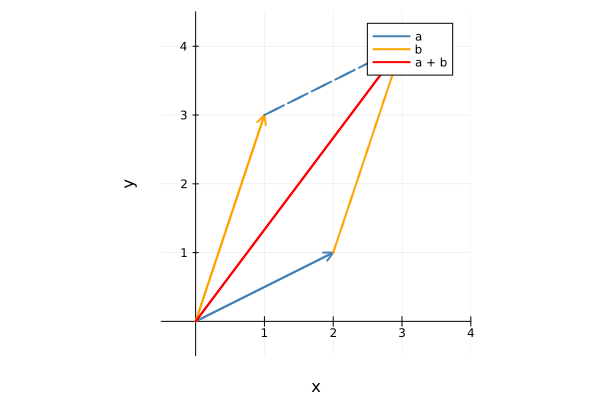

In [10]:
# Julia のベクトルとして受け取り，図示する
va, vb = to_value(weval(MathLink.parseexpr(a))), to_value(weval(MathLink.parseexpr(b)))

plane((-0.5, 4), (-0.5, 4.5))
arrow!([0, 0], va; color=:steelblue, label="a")
arrow!([0, 0], vb; color=:orange, label="b")
arrow!([0, 0], va + vb; color=:red, label="a + b")
arrow!(va, vb; color=:orange, ls=:dash, label="")
arrow!(vb, va; color=:steelblue, ls=:dash, label="")

### 垂直・平行の条件，単位ベクトル，正射影

In [11]:
calc("t /. First[Solve[{2, 1}.{t, 3} == 0, t]]"; lhs="(2,1) \\perp (t,3) \\iff t")             # 垂直：内積 = 0
calc("t /. First[Solve[Det[{{2, 1}, {t, 3}}] == 0, t]]"; lhs="(2,1) \\parallel (t,3) \\iff t")   # 平行：行列式 = 0
ew = calc("Normalize[{3, 4}]"; lhs="(3,4) \\text{ と同じ向きの単位ベクトル}")
prw = calc("Projection[{2, 3}, {4, 1}]"; lhs="(2,3) \\text{ の } (4,1) \\text{ への正射影}")

to_value(ew), to_value(prw)                # 成分は分数のまま

(Rational{Int64}[3//5, 4//5], Rational{Int64}[44//17, 11//17])

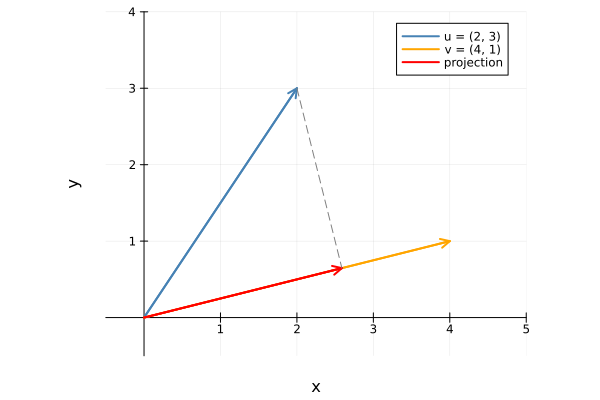

In [12]:
u, v = [2, 3], [4, 1]
pr = to_value(prw)

plane((-0.5, 5), (-0.5, 4))
arrow!([0, 0], u; color=:steelblue, label="u = (2, 3)")
arrow!([0, 0], v; color=:orange, label="v = (4, 1)")
arrow!([0, 0], fl(pr); color=:red, label="projection")
segment!(u, fl(pr); color=:gray, ls=:dash, label="")

In [13]:
dot(u .- pr, v)                             # 検算：u - (正射影) は v に垂直（分数のまま厳密に 0）

0//1

### $|\vec a + t\vec b|$ の最小値

$t$ を動かしたときの $|\vec a + t\vec b|$ の最小値を，Wolfram の `Minimize` で厳密に求めます。

In [14]:
fw = calc("Expand[($a + t $b).($a + t $b)]"; lhs="|\\vec a + t\\vec b|^2")       # |v|² = v・v
mw = weval(MathLink.parseexpr("Minimize[($a + t $b).($a + t $b), t]"))
showtex("\\min |\\vec a + t\\vec b|^2 = " * tex(mw.args[1]) * "\\quad \\left(" * ruletex(mw.args[2]) * "\\right)")

m2, at = to_value(mw)                       # 最小値（2 乗）と，そのときの t
sqrt(m2), at.t

(1.5811388300841898, -1//2)

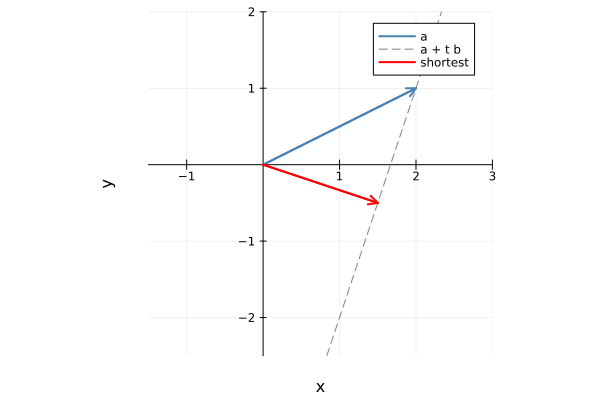

In [15]:
t0 = at.t
plane((-1.5, 3), (-2.5, 2))
arrow!([0, 0], va; color=:steelblue, label="a")
line!(va, va + vb; color=:gray, ls=:dash, label="a + t b")
arrow!([0, 0], fl(va + t0 * vb); color=:red, label="shortest")

In [16]:
dot(va + t0 * vb, vb)                       # 最小のとき，a + t b は b に垂直（内積が 0）

0//1

## 5. 三角形：面積と五心

3 点 $A(0, 0)$，$B(4, 0)$，$C(1, 3)$ を頂点とする三角形を調べます。

In [17]:
tri = "{{0, 0}, {4, 0}, {1, 3}}"
A, B, C = to_value(weval(MathLink.parseexpr(tri)))

Sw = calc("Area[Triangle[$tri]]"; lhs="S")
Gw = calc("TriangleCenter[Triangle[$tri], \"Centroid\"]"; lhs="\\text{重心 } G")
Ow = calc("TriangleCenter[Triangle[$tri], \"Circumcenter\"]"; lhs="\\text{外心 } O")
Hw = calc("TriangleCenter[Triangle[$tri], \"Orthocenter\"]"; lhs="\\text{垂心 } H")
Iw = calc("TriangleCenter[Triangle[$tri], \"Incenter\"]"; lhs="\\text{内心 } I", simplify=true)

G, O, H, I = to_value.([Gw, Ow, Hw, Iw])

4-element Vector{Vector}:
 Rational{Int64}[5//3, 1]
 [2, 1]
 [1, 1]
 [1.4598184865245474, 1.0521776337709472]

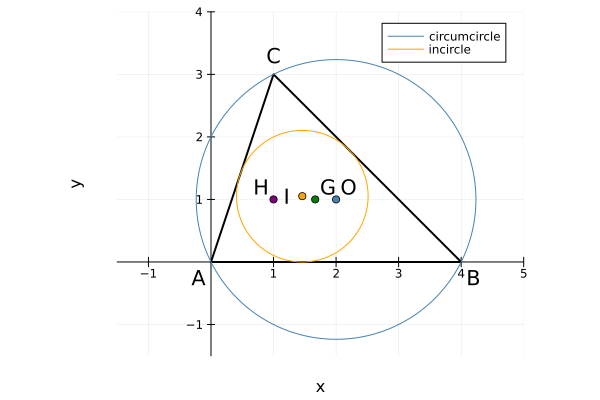

In [18]:
# 外接円・内接円（中心と半径）
cw = weval(MathLink.parseexpr("Circumsphere[$tri]"))                    # Sphere[中心, 半径] の形で返る
iw = weval(MathLink.parseexpr("FullSimplify[Insphere[$tri]]"))
showtex("\\text{外接円：中心 } " * vtex(tex(cw.args[1])) * ",\\ \\text{半径 } " * tex(cw.args[2]))
showtex("\\text{内接円：中心 } " * vtex(tex(iw.args[1])) * ",\\ \\text{半径 } " * tex(iw.args[2]))
(Oc, R), (Ic, r) = to_value(cw), to_value(iw)

plane((-1.5, 5), (-1.5, 4))
polygon!([A, B, C]; lw=2, color=:black, label="")
circle!(Oc, R; color=:steelblue, label="circumcircle")
circle!(Ic, r; color=:orange, label="incircle")
points!([G, O, H, I]; color=[:green, :steelblue, :purple, :orange], label="")
annotate!([(-0.2, -0.25, "A"), (4.2, -0.25, "B"), (1, 3.3, "C"),
           (G[1] + 0.2, G[2] + 0.2, "G"), (O[1] + 0.2, O[2] + 0.2, "O"), (H[1] - 0.2, H[2] + 0.2, "H"), (I[1] - 0.25, I[2], "I")])

**検算**（Julia 側）：面積は $\frac12|\det(\overrightarrow{AB}, \overrightarrow{AC})|$，外心は 3 頂点から等距離，内接円の半径は $r = \frac{2S}{a+b+c}$。  
また，外心 $O$・重心 $G$・垂心 $H$ は一直線上にあり，$\overrightarrow{OH} = 3\overrightarrow{OG}$ です（オイラー線）。

In [19]:
@show abs(det([B - A C - A])) / 2 to_value(Sw)
@show norm(A - O) norm(B - O) norm(C - O)
@show r 2 * to_value(Sw) / (norm(B - C) + norm(C - A) + norm(A - B))
@show H - O 3 * (G - O);                   # 分数のまま厳密に一致

abs(det([B - A C - A])) / 2 = 6.0
to_value(Sw) = 6
norm(A - O) = 2.23606797749979
norm(B - O) = 2.23606797749979
norm(C - O) = 2.23606797749979
r = 1.0521776337709472
(2 * to_value(Sw)) / (norm(B - C) + norm(C - A) + norm(A - B)) = 1.0521776337709476
H - O = [-1, 0]
3 * (G - O) = Rational{Int64}[-1, 0]


### 内分点・外分点

線分 $AB$ を $m : n$ に内分する点は $\dfrac{n\vec a + m\vec b}{m + n}$ です。

In [20]:
Dw = calc("(3 {0, 0} + 2 {4, 0})/(2 + 3)"; lhs="AB \\text{ を } 2:3 \\text{ に内分する点 } D")
Ew = calc("(-1 {4, 0} + 3 {1, 3})/(3 - 1)"; lhs="BC \\text{ を } 3:1 \\text{ に外分する点 } E")
Mw = calc("({4, 0} + {1, 3})/2"; lhs="BC \\text{ の中点 } M")

# 中線 AM を 2 : 1 に内分する点が重心
to_value(weval(W`(1 {0, 0} + 2 {5/2, 3/2})/3`)), G

(Rational{Int64}[5//3, 1], Rational{Int64}[5//3, 1])

## 6. 直線と円

### 2 直線の交点（媒介変数）

直線 $\ell_1 : (1, 2) + s(2, 1)$ と $\ell_2 : (5, 0) + t(-1, 2)$ の交点を，$s, t$ の連立方程式として解きます。

In [21]:
stw = weval(W`First[Solve[{1, 2} + s {2, 1} == {5, 0} + t {-1, 2}, {s, t}]]`)
showtex(ruletex(stw))
st = to_value(stw)                          # (s = 6//5, t = 8//5)

P = [1, 2] + st.s * [2, 1]
P, [5, 0] + st.t * [-1, 2]                  # どちらの式でも同じ点

(Rational{Int64}[17//5, 16//5], Rational{Int64}[17//5, 16//5])

### 点と直線の距離・垂線の足

2 点 $(0, 1)$，$(2, 0)$ を通る直線 $\ell$ と，点 $Q(3, 4)$。

to_value(dw_) = 4.024922359499621
norm(Q - Ft) = 4.024922359499622
dot(Q - Ft, [2, -1]) = 0//1


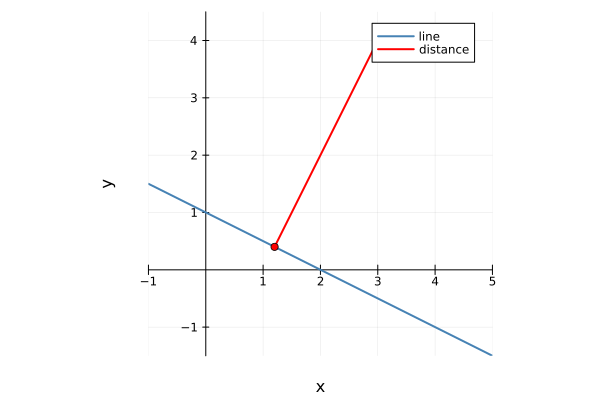

In [22]:
dw_ = calc("RegionDistance[InfiniteLine[{{0, 1}, {2, 0}}], {3, 4}]"; lhs="d(Q, \\ell)")
Fw  = calc("RegionNearest[InfiniteLine[{{0, 1}, {2, 0}}], {3, 4}]"; lhs="\\text{垂線の足 } F")

Q, Ft = [3, 4], to_value(Fw)
@show to_value(dw_) norm(Q - Ft)
@show dot(Q - Ft, [2, -1]);                 # QF は直線の方向ベクトル (2, -1) に垂直

plane((-1, 5), (-1.5, 4.5))
line!([0, 1], [2, 0]; color=:steelblue, lw=2, label="line")
segment!(Q, fl(Ft); color=:red, lw=2, label="distance")
points!([Q, Ft]; color=:red, label="")

### 円と直線の交点，円の接線

円 $x^2 + y^2 = 25$ と直線 $x - 2y + 5 = 0$ の交点，および点 $P(7, 1)$ から円に引いた接線の接点を求めます。  
接点 $T$ では $\overrightarrow{OT} \perp \overrightarrow{PT}$ なので，$\overrightarrow{OT} \cdot \overrightarrow{PT} = 0$ を条件にします。

In [23]:
xw = weval(W`{x, y} /. Solve[{x^2 + y^2 == 25, x - 2 y + 5 == 0}, {x, y}]`)
showtex("\\text{交点}\\quad " * ptstex(xw))
X = to_value(xw)                            # 点（ベクトル）の配列

tw = weval(W`{x, y} /. Solve[{x^2 + y^2 == 25, {x, y}.({x, y} - {7, 1}) == 0}, {x, y}]`)
showtex("\\text{接点}\\quad " * ptstex(tw))
T = to_value(tw)

2-element Vector{Vector{Int64}}:
 [3, 4]
 [4, -3]

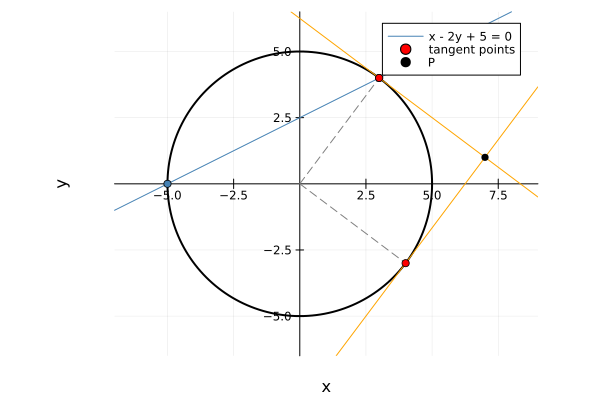

In [24]:
Pt = [7, 1]
plane((-7, 9), (-6.5, 6.5))
circle!([0, 0], 5; color=:black, lw=2, label="")
line!([-5, 0], [3, 4]; color=:steelblue, label="x - 2y + 5 = 0")
points!(X; color=:steelblue, label="")
for q in T
    line!(Pt, q; ext=1.5, color=:orange, label="")
    segment!([0, 0], q; color=:gray, ls=:dash, label="")
end
points!(T; color=:red, label="tangent points")
points!([Pt]; color=:black, label="P")

### ベクトル方程式が表す図形

2 点 $A(1, 2)$，$B(5, 4)$ に対して，$(\vec p - \vec a) \cdot (\vec p - \vec b) = 0$ を満たす点 $P(x, y)$ の全体は，$AB$ を直径とする円です。

In [25]:
ew_ = calc("Expand[({x, y} - {1, 2}).({x, y} - {5, 4})]"; lhs="(\\vec p - \\vec a)\\cdot(\\vec p - \\vec b)")
Fxy = to_function(ew_, :x, :y)

# 中心は AB の中点 (3, 3)，半径は |AB|/2 = √5 のはず：円周上の点で 0 になることを確かめる
[Fxy(3 + sqrt(5) * cos(t), 3 + sqrt(5) * sin(t)) for t in (0.0, 1.0, 2.5)]

3-element Vector{Float64}:
  0.0
  0.0
 -3.552713678800501e-15

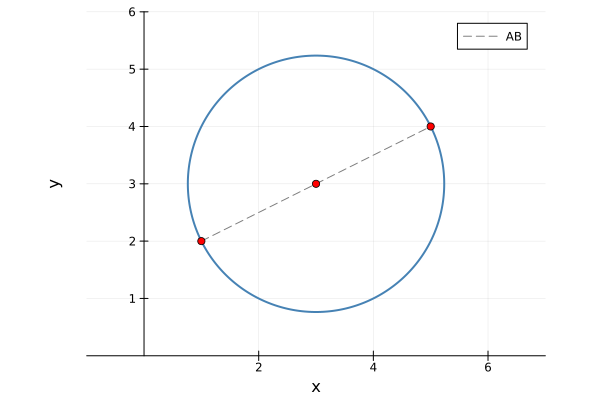

In [26]:
g = range(-1, 7; length=300)
plane((-1, 7), (0, 6))
contour!(g, g, (x, y) -> Fxy(x, y); levels=[0.0], colorbar=false, color=:steelblue, lw=2)
segment!([1, 2], [5, 4]; color=:gray, ls=:dash, label="AB")
points!([[1, 2], [5, 4], [3, 3]]; color=:red, label="")

## 7. 空間のベクトルと図形

### 外積

$\vec a \times \vec b$ は $\vec a$，$\vec b$ の両方に垂直で，大きさは $\vec a$，$\vec b$ が作る平行四辺形の面積です。

In [27]:
a3 = "{1, 2, 3}"; b3 = "{2, 0, 1}"

nw = calc("Cross[$a3, $b3]")
calc("Cross[$a3, $b3].$a3"; lhs="(\\vec a \\times \\vec b)\\cdot\\vec a")
calc("Cross[$a3, $b3].$b3"; lhs="(\\vec a \\times \\vec b)\\cdot\\vec b")
calc("Norm[Cross[$a3, $b3]]"; lhs="|\\vec a \\times \\vec b|")
calc("VectorAngle[$a3, $b3]"; lhs="\\theta");

to_value(nw), cross([1, 2, 3], [2, 0, 1])           # Julia の cross と一致

([2, 5, -4], [2, 5, -4])

### 3 点を通る平面

$A(1, 1, 0)$，$B(1, 0, 2)$，$C(0, 2, 1)$ を通る平面。法線ベクトルは $\overrightarrow{AB} \times \overrightarrow{AC}$，方程式は $\vec n \cdot (\vec p - \vec a) = 0$ です。

In [28]:
pA = "{1, 1, 0}"; pB = "{1, 0, 2}"; pC = "{0, 2, 1}"

nw = calc("Cross[$pB - $pA, $pC - $pA]"; lhs="\\vec n = \\overrightarrow{AB} \\times \\overrightarrow{AC}")
plw = calc("Expand[Cross[$pB - $pA, $pC - $pA].({x, y, z} - $pA)]"; lhs="\\vec n \\cdot (\\vec p - \\vec a)")
showtex("\\text{平面の方程式}\\quad " * tex(plw) * " = 0")

Sw3 = calc("Area[Triangle[{$pA, $pB, $pC}]]"; lhs="\\triangle ABC")
n = to_value(nw)
to_value(Sw3), norm(n) / 2                          # 面積 = |AB × AC| / 2

(1.8708286933869707, 1.8708286933869707)

### 点と平面の距離，垂線の足，四面体の体積

点 $P(3, 3, 3)$ から平面 $ABC$ に下ろした垂線の足 $H$ と距離，四面体 $PABC$ の体積を求めます。

In [29]:
pl = "InfinitePlane[{$pA, $pB, $pC}]"
dw3 = calc("RegionDistance[$pl, {3, 3, 3}]"; lhs="d(P, ABC)")
Hw3 = calc("RegionNearest[$pl, {3, 3, 3}]"; lhs="\\text{垂線の足 } H")
Vw  = calc("Volume[Tetrahedron[{{3, 3, 3}, $pA, $pB, $pC}]]"; lhs="V")

A3, B3, C3, P3 = [1, 1, 0], [1, 0, 2], [0, 2, 1], [3, 3, 3]
H3 = to_value(Hw3)
@show H3 P3 - H3                                    # PH は法線ベクトル n = (-3, -2, -1) に平行
@show to_value(dw3) norm(P3 - H3)
@show to_value(Vw) abs(det([A3 - P3 B3 - P3 C3 - P3])) / 6      # 体積 = |det| / 6
@show to_value(Sw3) * to_value(dw3) / 3;            # 体積 = 底面積 × 高さ / 3

H3 = Rational{Int64}[3//14, 8//7, 29//14]
P3 - H3 = Rational{Int64}[39//14, 13//7, 13//14]
to_value(dw3) = 3.474396144861517
norm(P3 - H3) = 3.4743961448615166
to_value(Vw) = 13//6
abs(det([A3 - P3 B3 - P3 C3 - P3])) / 6 = 2.1666666666666665
(to_value(Sw3) * to_value(dw3)) / 3 = 2.1666666666666665


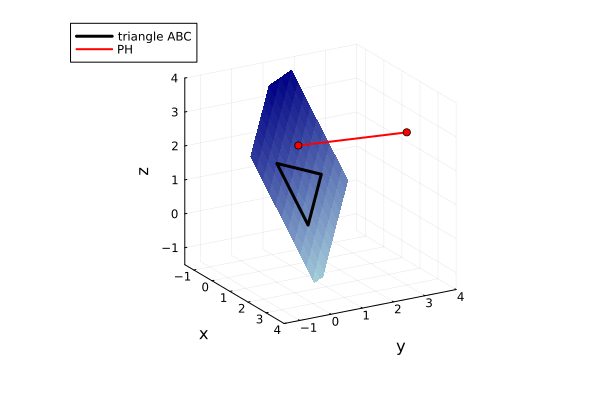

In [30]:
# 3 次元で描く：平面は A + s AB + t AC（s, t を動かす）で表す。3 軸の目盛りの幅をそろえて，垂直が垂直に見えるようにする
ss = range(-0.6, 1.6; length=12)
X = [A3[1] + s * (B3 - A3)[1] + t * (C3 - A3)[1] for s in ss, t in ss]
Y = [A3[2] + s * (B3 - A3)[2] + t * (C3 - A3)[2] for s in ss, t in ss]
Z = [A3[3] + s * (B3 - A3)[3] + t * (C3 - A3)[3] for s in ss, t in ss]

surface(X, Y, Z; alpha=0.35, color=:blues, colorbar=false, xlims=(-1.5, 4), ylims=(-1.5, 4), zlims=(-1.5, 4),
        xlabel="x", ylabel="y", zlabel="z", camera=(60, 20), legend=:topleft)
tri3 = [A3, B3, C3, A3]
plot!(getindex.(tri3, 1), getindex.(tri3, 2), getindex.(tri3, 3); color=:black, lw=3, label="triangle ABC")
plot!([P3[1], H3[1]], [P3[2], H3[2]], [P3[3], H3[3]]; color=:red, lw=2, label="PH")
scatter!([P3[1], Float64(H3[1])], [P3[2], Float64(H3[2])], [P3[3], Float64(H3[3])]; color=:red, label="")

### 直線と平面・球の交点

直線 $(1, 2, 3) + t(1, -1, 2)$ と平面 $2x + y - z = 4$ の交点，原点を通り方向 $(1, 1, 1)$ の直線と球 $(x-1)^2 + (y-2)^2 + (z-3)^2 = 9$ の交点を求めます。

In [31]:
qw = weval(W`First[Solve[{x, y, z} == {1, 2, 3} + t {1, -1, 2} && 2 x + y - z == 4, {x, y, z, t}]]`)
showtex("\\text{直線と平面}\\quad " * ruletex(qw))
q = to_value(qw)

sw3 = weval(W`Simplify[{x, y, z} /. Solve[{(x - 1)^2 + (y - 2)^2 + (z - 3)^2 == 9, {x, y, z} == t {1, 1, 1}}, {x, y, z, t}]]`)
showtex("\\text{直線と球}\\quad " * ptstex(sw3))
S = to_value(sw3)

2q.x + q.y - q.z, [norm(s - [1, 2, 3]) for s in S]      # 検算：平面の式 = 4，球の中心からの距離 = 3

(4, [3.0, 3.0])

## 8. うまくいかないとき

- **接続エラー（`AssertionError: nextpacket(...)` など）**：Wolfram Engine のカーネル数上限に達しています。他のノートブックのカーネルや `wolframscript` を止めてから，Julia カーネルを再起動してください。
- **ベクトルの書き方**：Wolfram では波かっこ `{1, 2}`，Julia では角かっこ `[1, 2]`。内積は Wolfram では `.`（ピリオド），Julia では `dot(a, b)`。
- **`*` は成分ごとの積**：Wolfram で `{1, 2} * {3, 4}` は `{3, 8}` になります。内積は必ず `.` を使います。
- **なす角がきれいな値にならない**：$\cos^{-1}(\cdots)$ の形で返ります。`to_value` でラジアンの数値にし，`rad2deg` で度に直せます。
- **文字を含むベクトルの大きさ**：`Norm[{a, b}]` は $\sqrt{|a|^2 + |b|^2}$ と絶対値つきで返ります。`Simplify[..., Element[{a, b}, Reals]]` で実数と指定します。
- **未対応の関数が出た**：エラーメッセージに出た名前を `WFUNC` に追加します。

In [32]:
θ2 = calc("VectorAngle[{1, 2, 2}, {3, 0, 4}]"; lhs="\\theta")
to_value(θ2), rad2deg(to_value(θ2))                 # ラジアンと度

(0.7475843496690209, 42.833428066067256)

In [33]:
calc("{1, 2} {3, 4}"; lhs="(1,2) * (3,4)\\ \\text{（成分ごとの積）}")
calc("{1, 2}.{3, 4}")
calc("Norm[{a, b}]")
calc("Simplify[Norm[{a, b}], Element[{a, b}, Reals]]"; lhs="|(a, b)|\\ (a, b \\text{ は実数})");